<div style="text-align: center; background: white; padding: 10px; display: inline-block; width: 100%;">
    <img src="logo_cc.png" width="400">
</div>

## Introduction
This project is a professional collaboration with `Ora Technologies` to build a machine learning model for their money-transferring application , `Ora Cash`. The primary goal is to predict user churn and identify at-risk users who are likely to delete their accounts. By understanding the factors contributing to churn, we aim to provide actionable insights to prevent account deletions and increase user activity on the app.

`Ora Cash` is a financial application that allows users to transfer money seamlessly. However, like many subscription-based services, retaining users is a critical challenge. Users may delete their accounts for various reasons, including: Dissatisfaction with the service , Switching to a competitor , No longer needing the service.

To address this, we will analyze `user` behavior and `transaction` data to identify patterns and features that contribute to churn. The insights derived from this analysis will help Ora Technologies implement targeted interventions to retain users and enhance their engagement with the app.

### Project Goals
The key objectives of this project are:
1. Build a predictive model to identify users at risk of churning.
2. Analyze and visualize important features contributing to churn.
3. Provide actionable insights to help Ora Technologies:
    - Retain at-risk users by implementing targeted interventions.
    - Increase user activity and engagement on the Ora Cash application.

By achieving these goals, we aim to enhance user retention and drive growth for Ora Technologies.

## Understanding the Datasets

### Dataset descriptions
For this project, we are working with two datasets provided by Ora Technologies : (1) a `users` dataset containing profile information (e.g., creation date, last activity, account deletion status) and (2) a `transactions` dataset recording all financial interactions (e.g., payment timestamps, amounts, methods) within Ora Cash application. The goal is to merge these datasets to analyze user behavior and predict churn—whether a user will delete their account in the future. By engineering features like transaction frequency, spending trends, and inactivity periods, we’ll build a model to identify at-risk users before they churn.

In [1]:
import pandas as pd
pd.set_option('display.max_colwidth', None)

In [2]:
# Users dataset description
users_descriptions = pd.read_csv("Users_descriptions.csv")
users_descriptions.style.set_properties(**{'text-align': 'left'})

,Column_Name,Description
0,User_Id,Unique identifier for the user
1,Phone_Number,User's phone number for authentication and contact
2,User_Type,"Type of user (CUSTOMER, MERCHANT)"
3,Gender,"User's gender (male, female)"
4,Created_At,Timestamp when the user account was created
5,Updated_At,Timestamp when the user account was last updated
6,Deleted_At,Timestamp when the user account was deleted (soft delete)
7,First_Name,User's first name
8,Last_Online,Timestamp when the user was last online
9,Is_Online,Boolean indicating if the user is currently online


In [3]:
# Transactions dataset description
transactions_descriptions = pd.read_csv("Transactions_descriptions.csv")
transactions_descriptions.style.set_properties(**{'text-align': 'left'})

,Column_Name,Description
0,User_Id,Unique identifier for the user
1,Phone_Number,Phone number associated with the account
2,Arn,Acquirer Reference Number (unique transaction ID)
3,Amount,Transaction amount (in DH)
4,Date_transaction,Date when the transaction occurred (YYYY-MM-DD format)
5,Time,Time when the transaction occurred (HH:MM:SS format)
6,Type_transaction,"Type of transaction (e.g., CASH IN EN MASSE, CASH IN, WALLET_TO_WALLET_CREDIT)"
7,Signature,"Transaction signature (C = Credit, D = Debit)"
8,First_Name,First name of the account holder


## Import Python Modules

First, we need to import the primary modules that will be used in this project like :
- pandas
- numpy
- Scipy
- Scikit-learn
- keras
- maplotlib
- seaborn
- etc, etc

In [4]:
# Import required packages

# Data packages
import pandas as pd
import numpy as np

# Machine Learning / Classification packages
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier

# Visualization Packages
from matplotlib import pyplot as plt
import seaborn as sns
import plotly.express as px
%matplotlib inline

In [5]:
# importing decision tree classifier from sklearn library
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import OneHotEncoder

In [7]:
pip install openpyxl

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 25.1
[notice] To update, run: C:\Users\USER\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


## Load the Data

We start by loading the excel file `FinalDBOraCash.xlsx` into two dataframes `users`, and `transactions` and display the shape of them.

In [8]:
#Loading users
users = pd.read_excel('FinalDBOraCash.xlsx', sheet_name='UserOraCash_anonyme')
print('users Shape:', users.shape)
users.head()

users Shape: (13203, 16)


,id,phoneNumber,userType,gender,createdAt,updatedAt,deletedAt,firstName,lastOnline,isOnline,avatar,mustPayMonthlyFee,enableMessagesNotification,enableTransactionsNotification,language,walletType
0,d08cfe7e-a2ed-4fdf-8ebb-f2104b1bf657,212601705767,CUSTOMER,MALE,2025-01-25 22:20:53.566,2025-01-25 22:24:54.162,NaT,EL MUSTAPHA,2025-01-25 22:24:54.141,f,"{""large"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/1.jpg"", ""small"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/1.jpg"", ""medium"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/1.jpg""}",f,t,t,en,WALLET_200
1,f5a9d798-00e0-4c6c-ae41-56e8c2b29b47,212634201652,CUSTOMER,MALE,2025-03-02 04:14:34.529,2025-03-02 04:17:13.600,NaT,TAOUFIK,2025-03-02 04:17:13.576,f,"{""large"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/12.jpg"", ""small"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/12.jpg"", ""medium"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/12.jpg""}",f,t,t,ar-FR,WALLET_200
2,27ee6b57-8043-4aae-9fdf-9e07b2862b34,212620225129,CUSTOMER,MALE,2025-01-22 07:11:10.252,2025-01-26 22:57:49.909,NaT,Bilal,2025-01-26 22:57:49.873,f,"{""large"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/16.jpg"", ""small"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/16.jpg"", ""medium"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/16.jpg""}",f,t,t,en,WALLET_200
3,cf72657e-4a71-4a05-9dfb-ac15d95fbfa9,212674197653,CUSTOMER,FEMALE,2024-11-19 14:33:57.428,2024-11-19 14:58:56.101,NaT,Amina,2024-11-19 14:58:56.074,f,"{""large"": ""https://staging-bucket.ora.ma/ora/common/avatars/female/10.jpg"", ""small"": ""https://staging-bucket.ora.ma/ora/common/avatars/female/10.jpg"", ""medium"": ""https://staging-bucket.ora.ma/ora/common/avatars/female/10.jpg""}",f,t,t,fr,WALLET_20000
4,458d9f2b-c65c-4ec5-8c50-02f1ddf7eb15,212689323565,CUSTOMER,MALE,2025-01-18 21:23:50.171,2025-01-19 14:38:28.732,NaT,WaliD,2025-01-19 14:38:28.708,f,"{""large"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/1.jpg"", ""small"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/1.jpg"", ""medium"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/1.jpg""}",f,t,t,ar,WALLET_200


In [9]:
#Loading transactions
transactions = pd.read_excel('FinalDBOraCash.xlsx', sheet_name='TransRec_anonyme')
print('transactions Shape:', transactions.shape)
transactions.head()

transactions Shape: (2678, 9)


,User Id,num_phone,arn,montant,date_transaction,Time,type_transaction,sig,prenom
0,NaN,NaN,7.111111e+22,1.0,2024-11-13,18:19:46,CASH IN EN MASSE,C,ASMAA
1,NaN,NaN,7.111111e+22,33.0,2024-11-13,19:50:55,CASH IN,C,ASMAA
2,6ee30034-01a4-4f12-853f-d23df6e9f6b4,2.126004e+11,7.111111e+22,150.0,2024-11-14,16:14:06,WALLET_TO_WALLET_CREDIT,C,AYOUB
3,6ee30034-01a4-4f12-853f-d23df6e9f6b4,2.126004e+11,7.111111e+22,433.0,2024-11-15,11:15:32,WALLET_TO_WALLET_DEBIT,D,AYOUB
4,5e9b6917-572b-400c-a249-4d90e644ac28,2.126548e+11,7.111111e+22,10.0,2024-11-15,16:18:02,PAIMENT_FACTURE,D,mohammed


## Data Exploration and Cleaning:

The data cleaning phase involves standardizing raw datasets (users and transactions) by handling missing values, correcting inconsistent formats (e.g., phone numbers, dates), validating categorical fields (e.g., transaction types), and removing duplicates or invalid entries.

In [10]:
#Checking for missing values in users
print('Missing values in users:')
users.isnull().sum()

Missing values in users:


id                                    0
phoneNumber                           0
userType                              0
gender                              118
createdAt                             0
updatedAt                             0
deletedAt                         12349
firstName                             0
lastOnline                            0
isOnline                              0
avatar                              347
mustPayMonthlyFee                     0
enableMessagesNotification            0
enableTransactionsNotification        0
language                              0
walletType                            0
dtype: int64

In [11]:
#Checking for missing values in transactions
print('Missing values in transactions:')
transactions.isnull().sum()

Missing values in transactions:


User Id              84
num_phone            84
arn                   0
montant               0
date_transaction      0
Time                  0
type_transaction      0
sig                 224
prenom              224
dtype: int64

In [12]:
# Extract the first four digits of the phone numbers
Phone_Prefix = users['phoneNumber'].astype(str).str[:4]

# Count the occurrences of each prefix
Phone_Prefix.value_counts()

phoneNumber
2126    13203
Name: count, dtype: int64

- The phone prefix has one unique value, so we can't extract more informations from phone numbers.

In [13]:
def clean_users(df):
    # Rename columns based on descriptions
    df.columns = users_descriptions["Column_Name"].values

    # Handle duplicates
    df = df.drop_duplicates(subset=['User_Id'])
    
    # Process the First_Name column in users_clean
    df['First_Name'] = df['First_Name'].str.split().str[0].str.lower()
    
    # Validate user IDs
    df = df[df['User_Id'].notna()]
    
    # Delete Phone_Number column
    df = df.drop(['Phone_Number'], axis=1)
    
    # Handle NaN values
    df['Gender'] = df['Gender'].fillna('Unknown')
    df['Deleted_At'] = df['Deleted_At'].fillna(pd.NaT)
    df['Avatar'] = df['Avatar'].fillna('No Avatar')
    return df

In [14]:
def clean_transactions(df):
    # Rename columns based on descriptions
    df.columns = transactions_descriptions["Column_Name"].values
    
    
    # Handle monetary values
    df['Amount'] = pd.to_numeric(df['Amount'], errors='coerce')
    df = df[df['Amount'] > 0]  # Remove negative amounts
    
    # Clean categoricals
    df['Signature'] = df['Signature'].str.upper().replace(['C','D'], ['Credit','Debit'])
    df['Type_transaction'] = df['Type_transaction'].str.lower().str.strip()
    
    

    # Process the First_Name column in transactions_clean
    df['First_Name'] = df['First_Name'].str.split().str[0].str.lower()
    # Delete ARNs
    df = df.drop(['Arn'], axis = 1)

    # Delete Phone_Number column
    df = df.drop(['Phone_Number'], axis=1)
    
    # Handle missing values
    df['User_Id'] = df['User_Id'].fillna('Unknown')  # Replace missing User_Id with 'Unknown'
    df['Signature'] = df['Signature'].fillna('Unknown')  # Replace missing Sig with 'Unknown'
    df['First_Name'] = df['First_Name'].fillna('No Name')  # Replace missing First_Name with 'No Name'
    
    return df

In [15]:
# Apply cleaning
users_clean = clean_users(users)
transactions_clean = clean_transactions(transactions)

In [16]:
users_clean.head()

,User_Id,User_Type,Gender,Created_At,Updated_At,Deleted_At,First_Name,Last_Online,Is_Online,Avatar,Must_Pay_Monthly_Fee,Enable_Messages_Notification,Enable_Transactions_Notification,Language,Wallet_Type
0,d08cfe7e-a2ed-4fdf-8ebb-f2104b1bf657,CUSTOMER,MALE,2025-01-25 22:20:53.566,2025-01-25 22:24:54.162,NaT,el,2025-01-25 22:24:54.141,f,"{""large"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/1.jpg"", ""small"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/1.jpg"", ""medium"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/1.jpg""}",f,t,t,en,WALLET_200
1,f5a9d798-00e0-4c6c-ae41-56e8c2b29b47,CUSTOMER,MALE,2025-03-02 04:14:34.529,2025-03-02 04:17:13.600,NaT,taoufik,2025-03-02 04:17:13.576,f,"{""large"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/12.jpg"", ""small"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/12.jpg"", ""medium"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/12.jpg""}",f,t,t,ar-FR,WALLET_200
2,27ee6b57-8043-4aae-9fdf-9e07b2862b34,CUSTOMER,MALE,2025-01-22 07:11:10.252,2025-01-26 22:57:49.909,NaT,bilal,2025-01-26 22:57:49.873,f,"{""large"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/16.jpg"", ""small"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/16.jpg"", ""medium"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/16.jpg""}",f,t,t,en,WALLET_200
3,cf72657e-4a71-4a05-9dfb-ac15d95fbfa9,CUSTOMER,FEMALE,2024-11-19 14:33:57.428,2024-11-19 14:58:56.101,NaT,amina,2024-11-19 14:58:56.074,f,"{""large"": ""https://staging-bucket.ora.ma/ora/common/avatars/female/10.jpg"", ""small"": ""https://staging-bucket.ora.ma/ora/common/avatars/female/10.jpg"", ""medium"": ""https://staging-bucket.ora.ma/ora/common/avatars/female/10.jpg""}",f,t,t,fr,WALLET_20000
4,458d9f2b-c65c-4ec5-8c50-02f1ddf7eb15,CUSTOMER,MALE,2025-01-18 21:23:50.171,2025-01-19 14:38:28.732,NaT,walid,2025-01-19 14:38:28.708,f,"{""large"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/1.jpg"", ""small"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/1.jpg"", ""medium"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/1.jpg""}",f,t,t,ar,WALLET_200


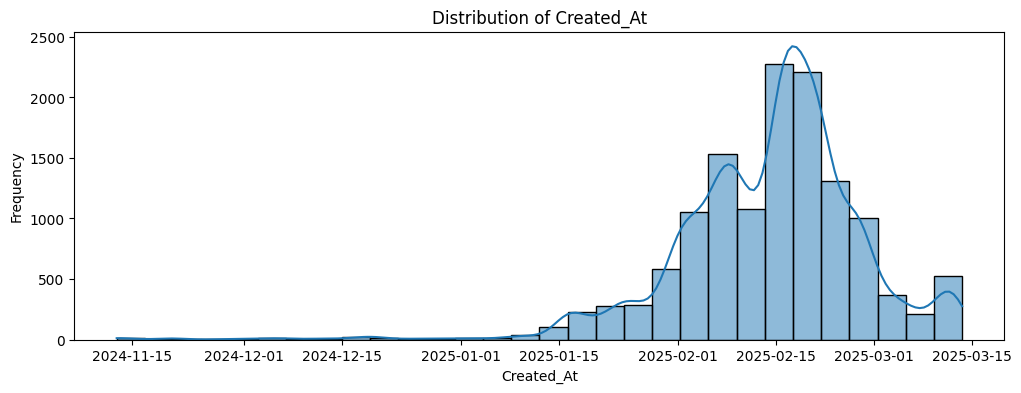

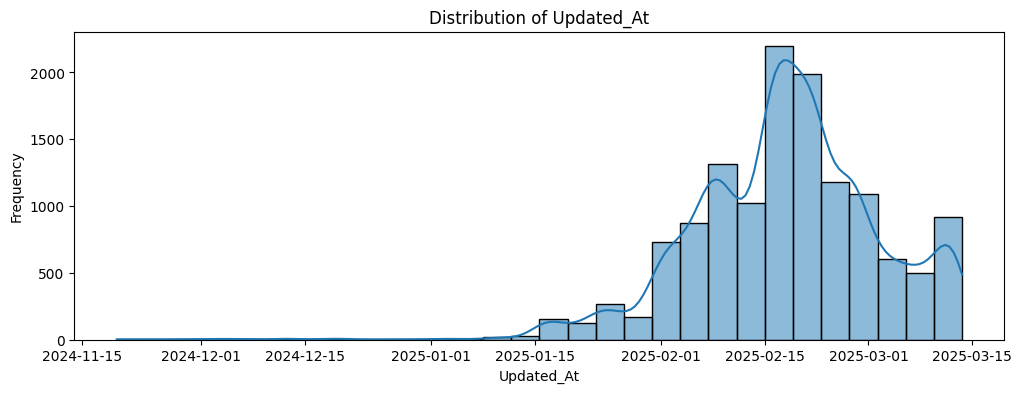

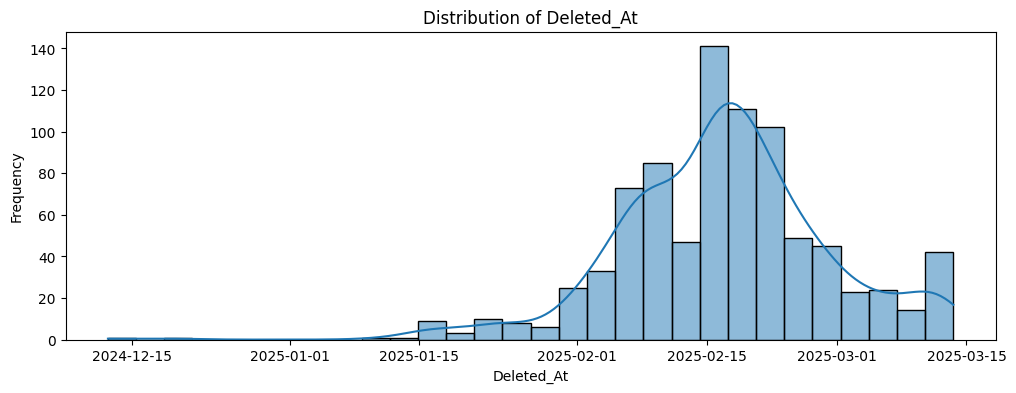

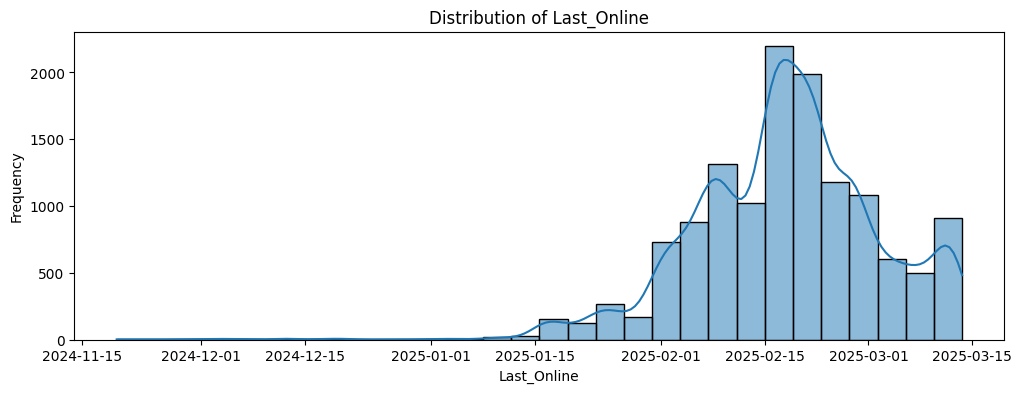

Index(['User_Type', 'Gender', 'Is_Online', 'Must_Pay_Monthly_Fee',
       'Enable_Messages_Notification', 'Enable_Transactions_Notification',
       'Language', 'Wallet_Type'],
      dtype='object')


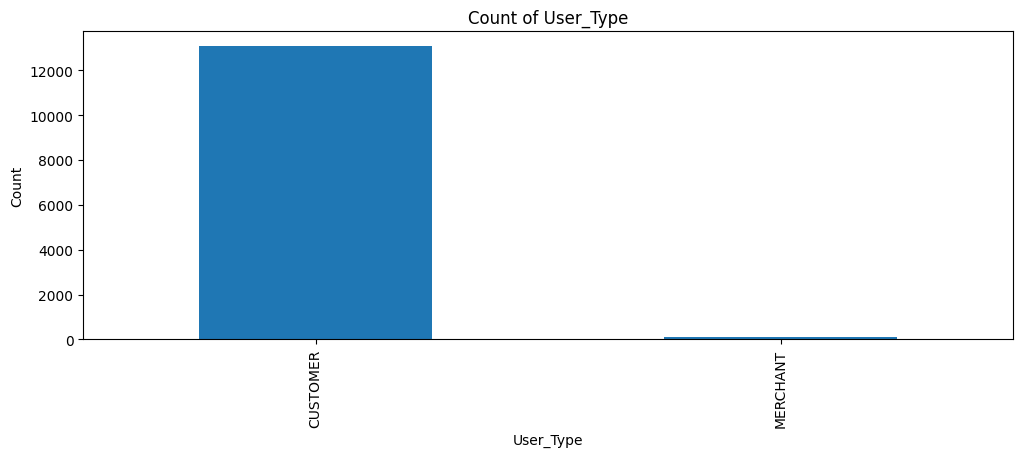

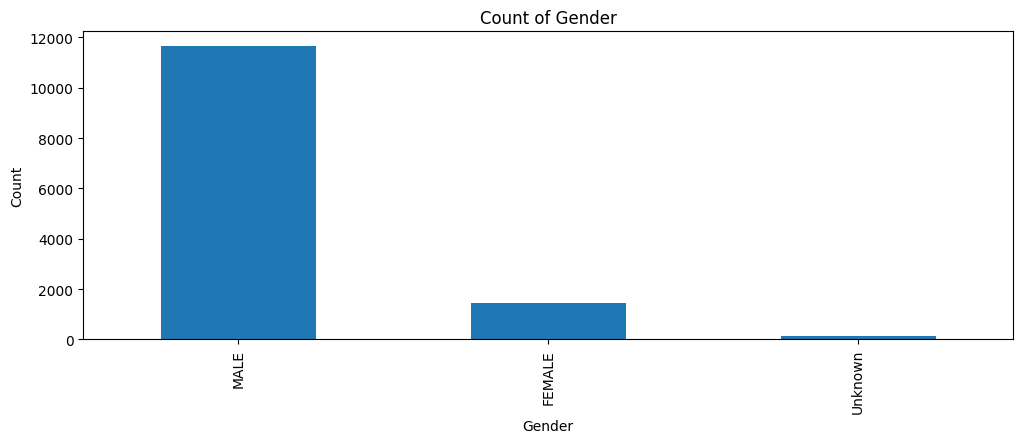

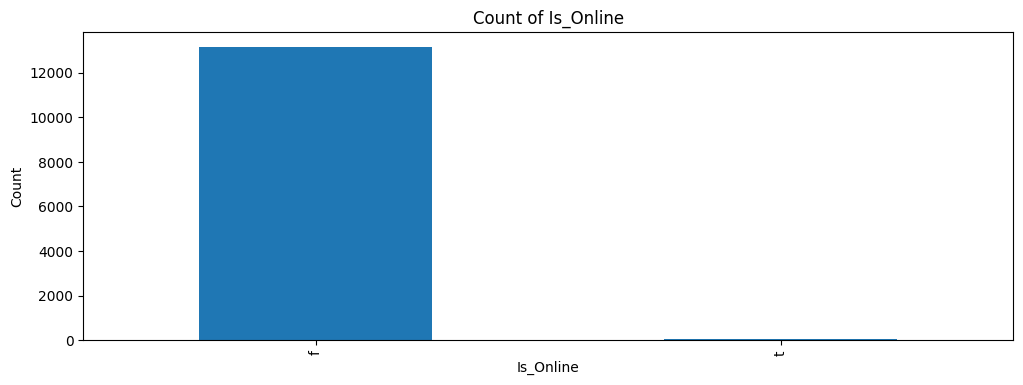

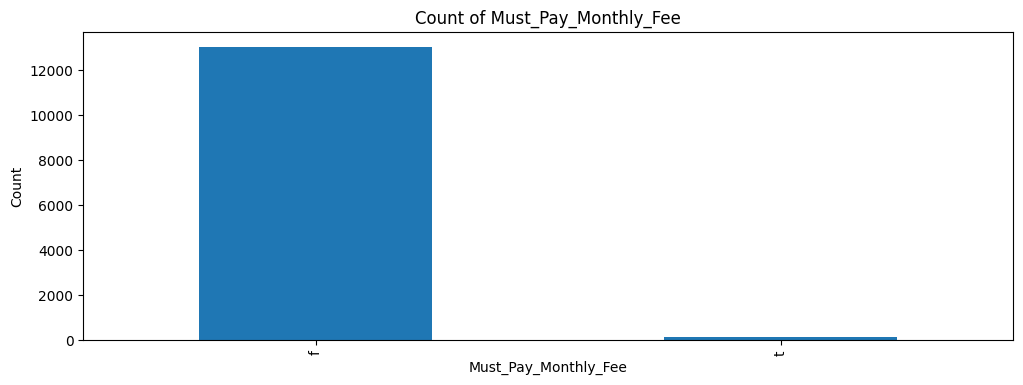

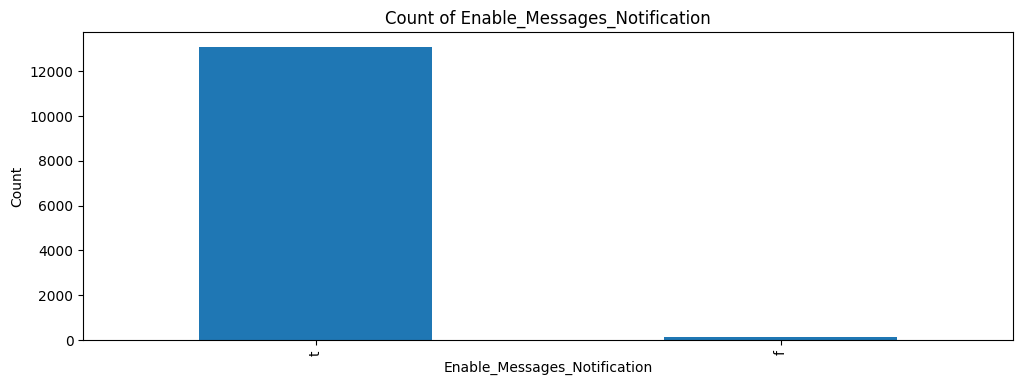

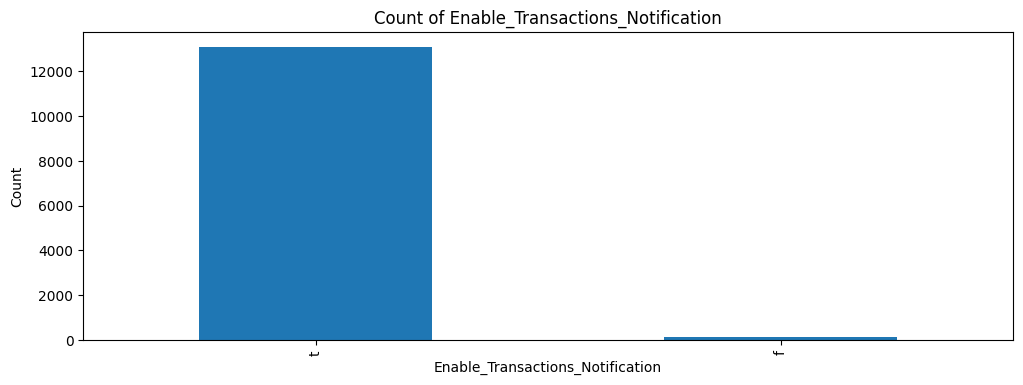

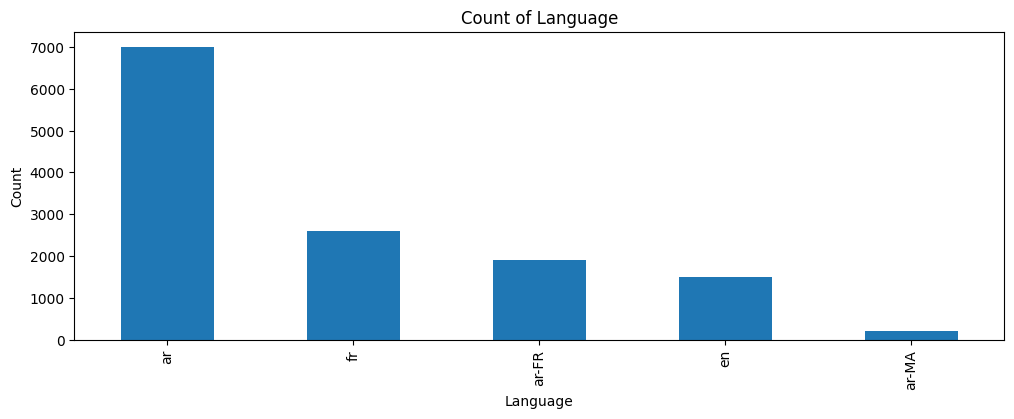

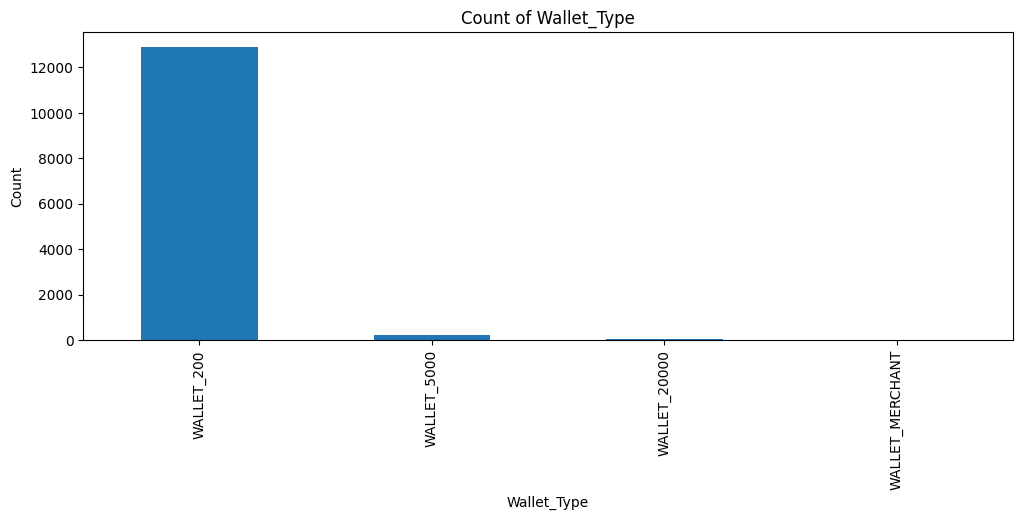

Text(0, 0.5, 'Count')

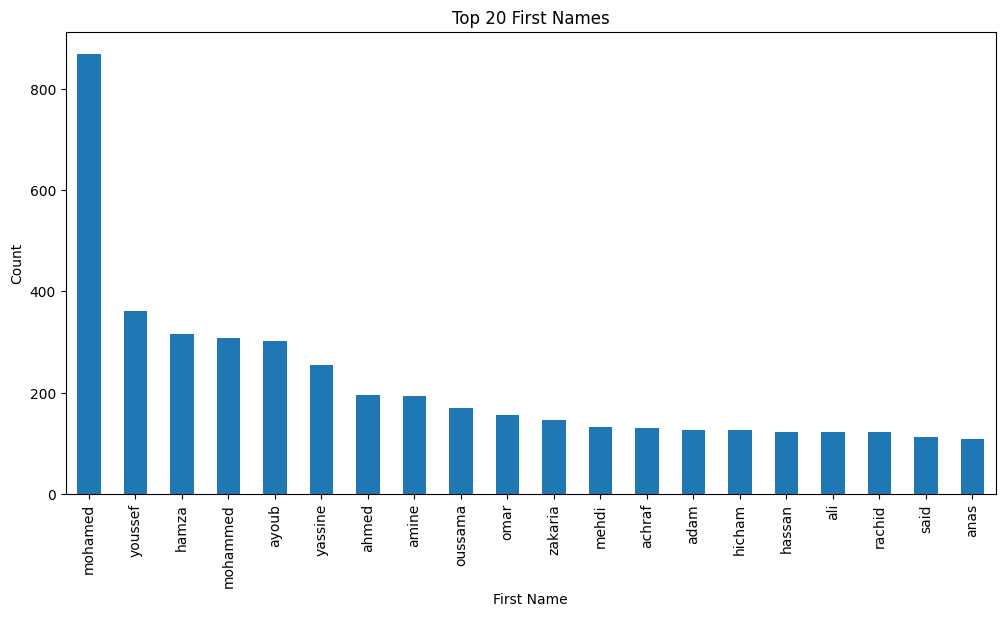

In [17]:
# Univariate analysis for numerical features in users_clean 
numerical_features = users_clean.select_dtypes(include=['int64', 'float64', 'datetime64[ns]']).columns
for feature in numerical_features:
    plt.figure(figsize=(12, 4))
    sns.histplot(users_clean[feature].dropna(), kde=True, bins=30)
    plt.title(f'Distribution of {feature}')
    plt.xlabel(feature)
    plt.ylabel('Frequency')
    plt.show()

# Univariate analysis for categorical features in users_clean
categorical_features = users_clean.select_dtypes(include=['object']).columns
categorical_features = categorical_features.drop(['User_Id','Avatar','First_Name'])  
print(categorical_features)  # Avatar and First_Name 
for feature in categorical_features:
    plt.figure(figsize=(12, 4))
    users_clean[feature].value_counts().plot(kind='bar')
    plt.title(f'Count of {feature}')
    plt.xlabel(feature)
    plt.ylabel('Count')
    plt.show()

# Visualizing the top 20 first names
top_20_names = users_clean['First_Name'].value_counts().head(20)
plt.figure(figsize=(12, 6))
top_20_names.plot(kind='bar')
plt.title('Top 20 First Names')
plt.xlabel('First Name')
plt.ylabel('Count')

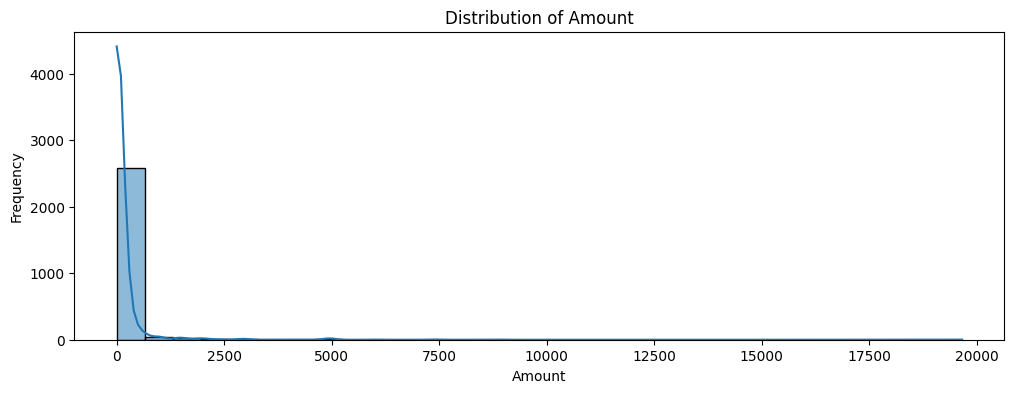

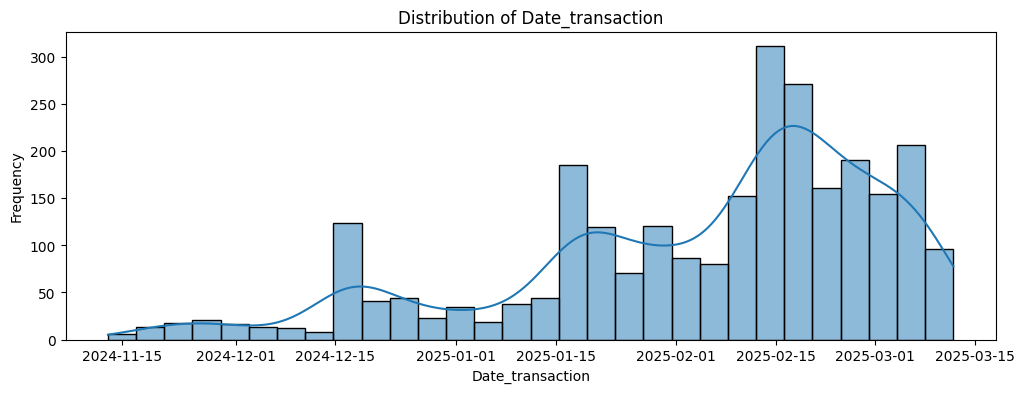

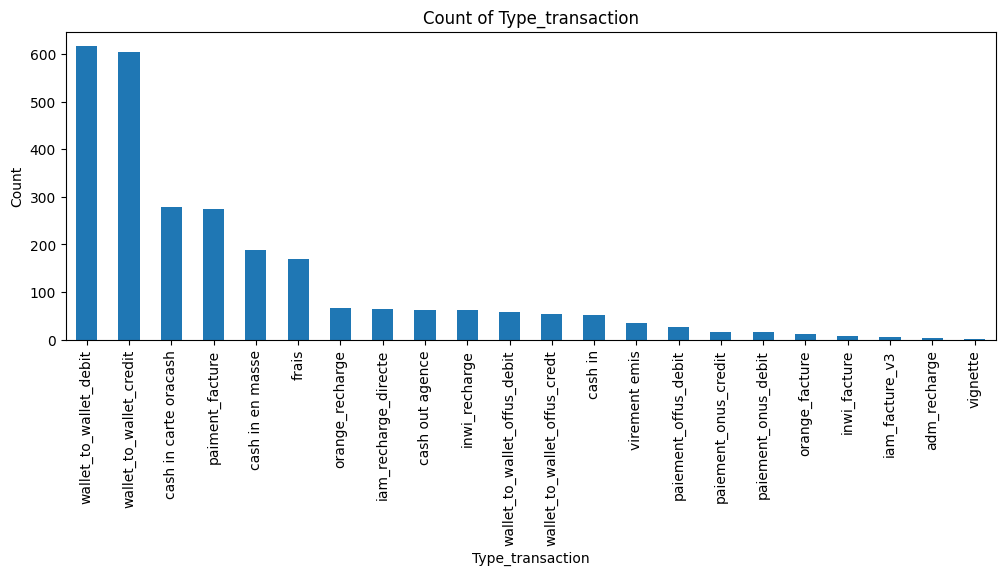

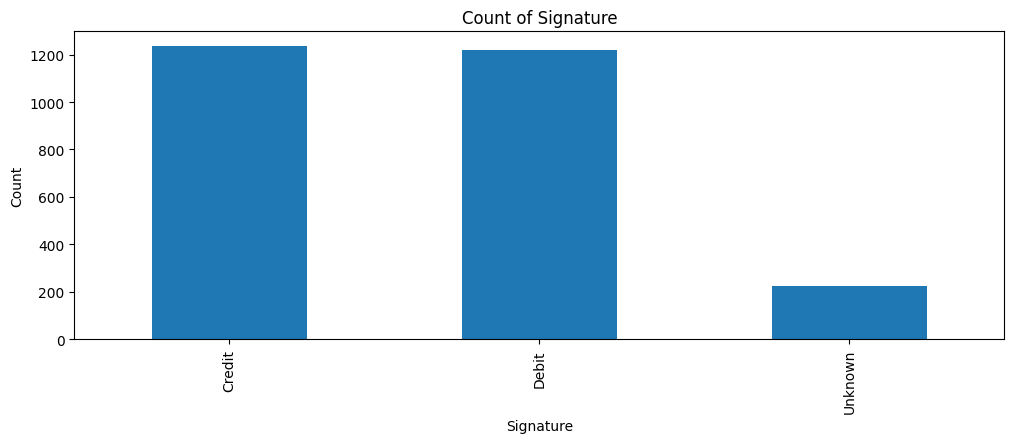

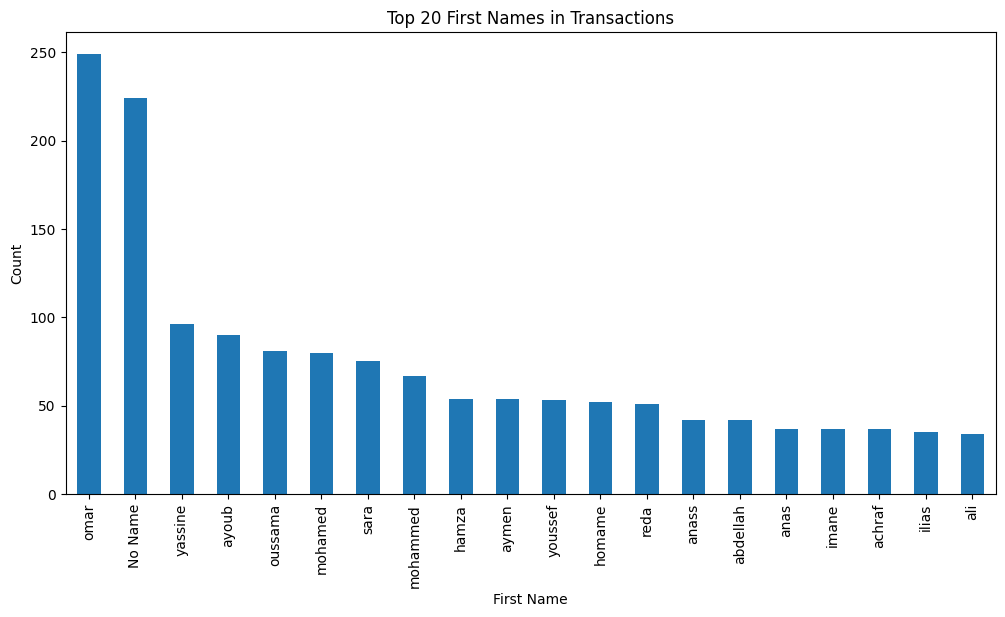

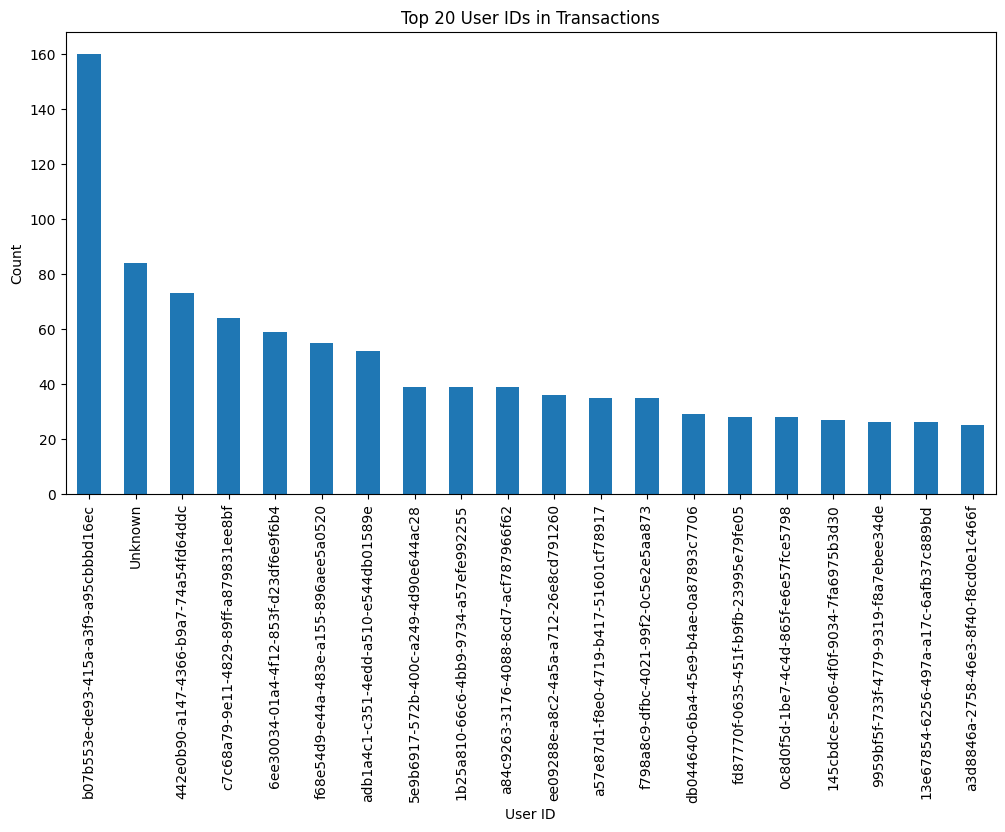

In [18]:
# Univariate analysis for numerical features in transactions
numerical_features = transactions_clean.select_dtypes(include=['int64', 'float64', 'datetime64[ns]']).columns
for feature in numerical_features:
    plt.figure(figsize=(12, 4))
    sns.histplot(transactions_clean[feature].dropna(), kde=True, bins=30)
    plt.title(f'Distribution of {feature}')
    plt.xlabel(feature)
    plt.ylabel('Frequency')
    plt.show()

# Univariate analysis for categorical features in transactions
categorical_features = transactions_clean.select_dtypes(include=['object']).columns
categorical_features = categorical_features.drop(['User_Id', 'First_Name', 'Time'])  # Exclude User_Id and First_Name
for feature in categorical_features:
    plt.figure(figsize=(12, 4))
    transactions_clean[feature].value_counts().plot(kind='bar')
    plt.title(f'Count of {feature}')
    plt.xlabel(feature)
    plt.ylabel('Count')
    
    plt.show()

# Visualizing the top 20 first names
top_20_names = transactions_clean['First_Name'].value_counts().head(20)
plt.figure(figsize=(12, 6))
top_20_names.plot(kind='bar')
plt.title('Top 20 First Names in Transactions')
plt.xlabel('First Name')
plt.ylabel('Count')
plt.show()

# Visualizing the top 20 User IDs
top_20_ids = transactions_clean['User_Id'].value_counts().head(20)
plt.figure(figsize=(12, 6))
top_20_ids.plot(kind='bar')
plt.title('Top 20 User IDs in Transactions')
plt.xlabel('User ID')
plt.ylabel('Count')
plt.show()

## Feature Engineering :

Feature engineering is a critical step in the machine learning pipeline that involves transforming raw data into meaningful features to improve the performance of predictive models. The primary goal is to extract, create, and refine features that capture the underlying patterns and relationships in the data, enabling the model to make accurate predictions. This process includes encoding categorical variables, scaling numerical features, and creating new features through domain knowledge or mathematical transformations. By enhancing the quality and relevance of the input data, feature engineering helps to reduce noise, improve model interpretability, and optimize predictive accuracy.

In [19]:
# Convert the Time column to timedelta
transactions_clean['Time'] = pd.to_timedelta(transactions_clean['Time'].astype(str))

# Combine Date_transaction and Time columns to create a proper datetime column
transactions_clean['Transaction_Datetime'] = transactions_clean['Date_transaction'] + transactions_clean['Time']

# Aggregating transaction features for each user
transaction_features = transactions_clean.groupby('User_Id').agg(
    num_transactions=('Amount', 'count'),
    avg_transaction_amount=('Amount', 'mean'),
    max_transaction_amount=('Amount', 'max'),
    min_transaction_amount=('Amount', 'min'),
    total_transaction_amount=('Amount', 'sum'),
    last_transaction_date=('Transaction_Datetime', 'max'),
    first_transaction_date=('Transaction_Datetime', 'min')
).reset_index()

# Calculating activity period for each user
transaction_features['activity_period'] = (
    transaction_features['last_transaction_date'] - transaction_features['first_transaction_date']
).dt.days

# Dropping the first and last transaction date columns as they are no longer needed
transaction_features = transaction_features.drop(columns=['last_transaction_date', 'first_transaction_date'])


# Merging transaction features with users_clean
users_clean = users_clean.merge(transaction_features, how='left', left_on='User_Id', right_on='User_Id')

# Creating churn target (1 if Deleted_At is not null, else 0)
users_clean['churn_target'] = users_clean['Deleted_At'].notna().astype(int)
# Calculate additional features
users_clean['account_duration'] = (users_clean['Updated_At'] - users_clean['Created_At']).dt.days
users_clean['activity_duration'] = (users_clean['Last_Online'] - users_clean['Created_At']).dt.days
users_clean['time_since_last_update'] = (pd.Timestamp.now() - users_clean['Updated_At']).dt.days

# Group by User_Id and aggregate features
users_features = users_clean.groupby('User_Id').agg({
    'account_duration': 'mean',
    'activity_duration': 'mean',
    'time_since_last_update': 'mean'
}).reset_index()

# Merge the aggregated features back into users_clean
users_clean = users_clean.merge(users_features, how='left', on='User_Id')
# Filling missing values for users with no transactions
users_clean.fillna({
    'num_transactions': 0,
    'avg_transaction_amount': 0,
    'max_transaction_amount': 0,
    'min_transaction_amount': 0,
    'total_transaction_amount': 0,
    'activity_period': 0
}, inplace=True)

users_clean.head()

,User_Id,User_Type,Gender,Created_At,Updated_At,Deleted_At,First_Name,Last_Online,Is_Online,Avatar,...,min_transaction_amount,total_transaction_amount,activity_period,churn_target,account_duration_x,activity_duration_x,time_since_last_update_x,account_duration_y,activity_duration_y,time_since_last_update_y
0,d08cfe7e-a2ed-4fdf-8ebb-f2104b1bf657,CUSTOMER,MALE,2025-01-25 22:20:53.566,2025-01-25 22:24:54.162,NaT,el,2025-01-25 22:24:54.141,f,"{""large"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/1.jpg"", ""small"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/1.jpg"", ""medium"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/1.jpg""}",...,0.0,0.0,0.0,0,0,0,90,0.0,0.0,90.0
1,f5a9d798-00e0-4c6c-ae41-56e8c2b29b47,CUSTOMER,MALE,2025-03-02 04:14:34.529,2025-03-02 04:17:13.600,NaT,taoufik,2025-03-02 04:17:13.576,f,"{""large"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/12.jpg"", ""small"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/12.jpg"", ""medium"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/12.jpg""}",...,0.0,0.0,0.0,0,0,0,55,0.0,0.0,55.0
2,27ee6b57-8043-4aae-9fdf-9e07b2862b34,CUSTOMER,MALE,2025-01-22 07:11:10.252,2025-01-26 22:57:49.909,NaT,bilal,2025-01-26 22:57:49.873,f,"{""large"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/16.jpg"", ""small"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/16.jpg"", ""medium"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/16.jpg""}",...,0.0,0.0,0.0,0,4,4,89,4.0,4.0,89.0
3,cf72657e-4a71-4a05-9dfb-ac15d95fbfa9,CUSTOMER,FEMALE,2024-11-19 14:33:57.428,2024-11-19 14:58:56.101,NaT,amina,2024-11-19 14:58:56.074,f,"{""large"": ""https://staging-bucket.ora.ma/ora/common/avatars/female/10.jpg"", ""small"": ""https://staging-bucket.ora.ma/ora/common/avatars/female/10.jpg"", ""medium"": ""https://staging-bucket.ora.ma/ora/common/avatars/female/10.jpg""}",...,0.0,0.0,0.0,0,0,0,158,0.0,0.0,158.0
4,458d9f2b-c65c-4ec5-8c50-02f1ddf7eb15,CUSTOMER,MALE,2025-01-18 21:23:50.171,2025-01-19 14:38:28.732,NaT,walid,2025-01-19 14:38:28.708,f,"{""large"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/1.jpg"", ""small"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/1.jpg"", ""medium"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/1.jpg""}",...,0.0,0.0,0.0,0,0,0,97,0.0,0.0,97.0


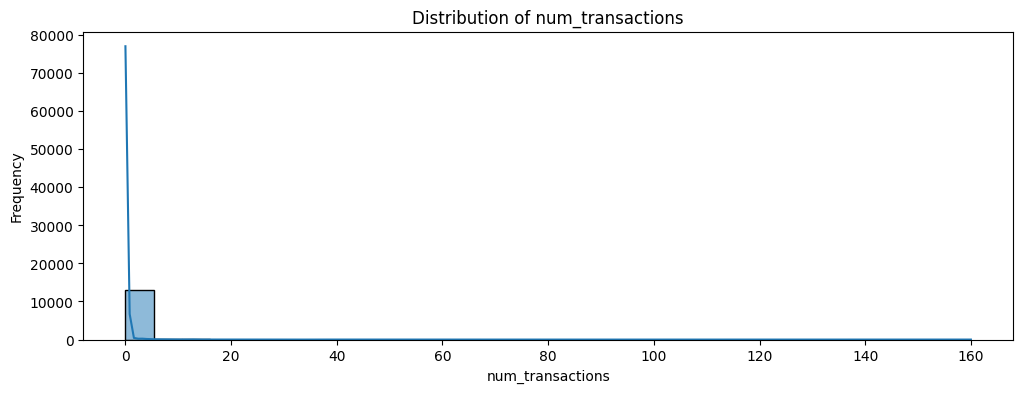

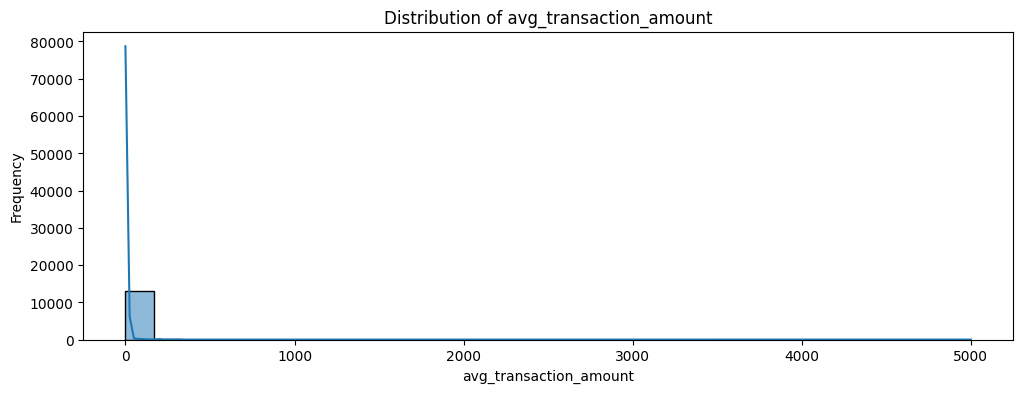

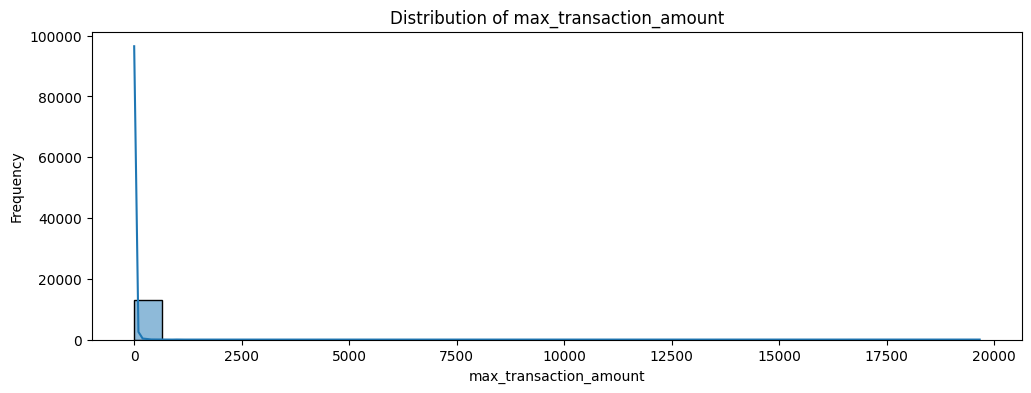

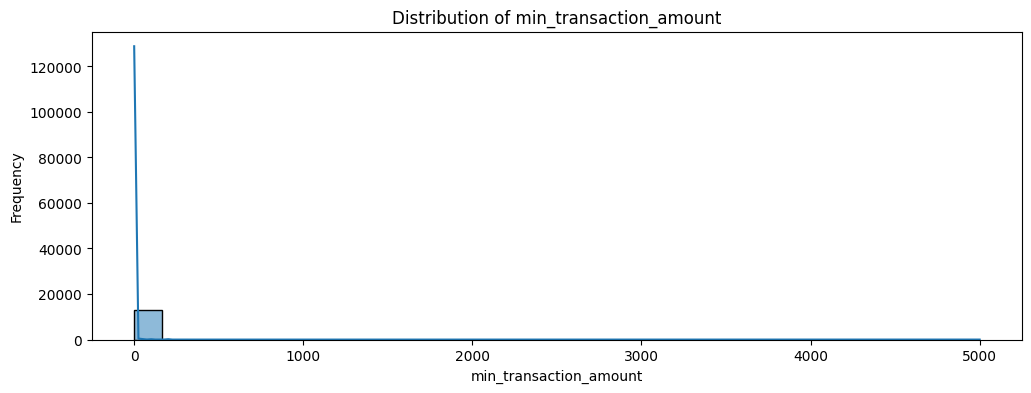

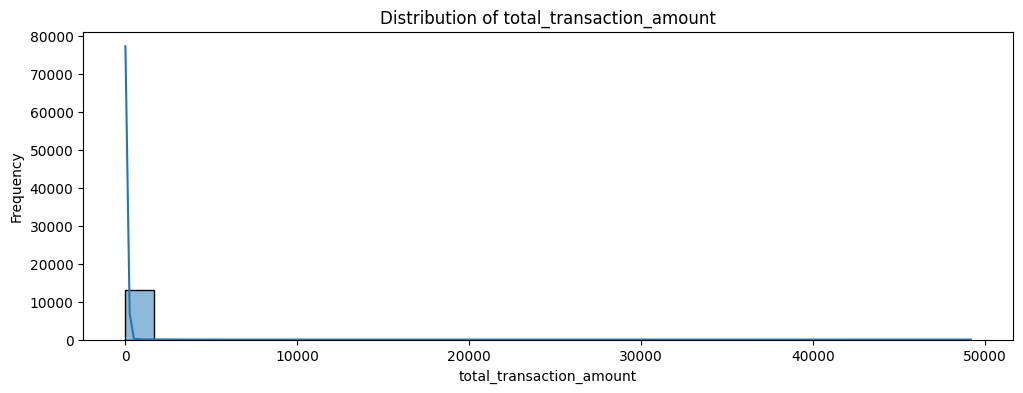

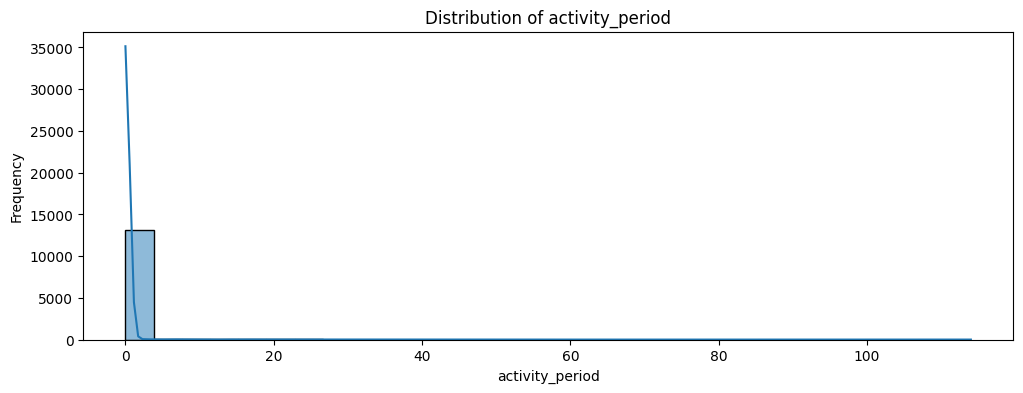

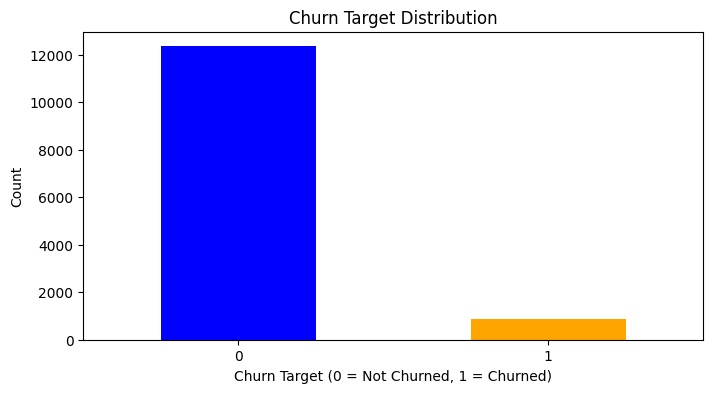

In [20]:
# Visualizing new numerical features
new_numerical_features = ['num_transactions', 'avg_transaction_amount', 'max_transaction_amount', 
                          'min_transaction_amount', 'total_transaction_amount', 'activity_period']

for feature in new_numerical_features:
    plt.figure(figsize=(12, 4))
    sns.histplot(users_clean[feature].dropna(), kde=True, bins=30)
    plt.title(f'Distribution of {feature}')
    plt.xlabel(feature)
    plt.ylabel('Frequency')
    plt.show()

# Visualizing the churn target
plt.figure(figsize=(8, 4))
users_clean['churn_target'].value_counts().plot(kind='bar', color=['blue', 'orange'])
plt.title('Churn Target Distribution')
plt.xlabel('Churn Target (0 = Not Churned, 1 = Churned)')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.show()

In [21]:
# Display all unique values in the Avatar column
# Extracting classes from Avatar links
users_clean['Avatar_Class'] = users_clean['Avatar'].apply(lambda x: 'common' if 'common' in x else 'users' if 'users' in x else 'unknown')

# Display unique values in the Avatar_Class column
users_clean['Avatar_Class'].unique()

# Drop the Avatar column as it is no longer needed
users_clean.drop(columns=['Avatar'], inplace=True)

In [22]:
# Identify categorical columns in users_clean
categorical_columns = users_clean.select_dtypes(include=['object']).columns

# Exclude 'First_Name', 'User_Id', and 'Avatar' from encoding
categorical_columns = categorical_columns.drop(['First_Name', 'User_Id'])

# Replace 't' with 1 and 'f' with 0 for columns with only two unique values
binary_columns = [col for col in categorical_columns if users_clean[col].nunique() == 2]
for col in binary_columns:
    users_clean[col] = users_clean[col].replace({'t': 1, 'f': 0})

# Remove binary columns from the list of columns to encode
categorical_columns = categorical_columns.drop(binary_columns)

# Perform one-hot encoding for the remaining categorical columns
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
encoded_data = encoder.fit_transform(users_clean[categorical_columns])

# Create a DataFrame for the encoded columns
encoded_columns = encoder.get_feature_names_out(categorical_columns)
encoded_df = pd.DataFrame(encoded_data, columns=encoded_columns, index=users_clean.index)

# Concatenate the encoded columns with the original DataFrame
users_clean_encoded = pd.concat([users_clean.drop(categorical_columns, axis=1), encoded_df], axis=1)

users_clean_encoded.head()

C:\Users\USER\AppData\Local\Temp\ipykernel_14004\2593552358.py:10: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  users_clean[col] = users_clean[col].replace({'t': 1, 'f': 0})


,User_Id,User_Type,Created_At,Updated_At,Deleted_At,First_Name,Last_Online,Is_Online,Must_Pay_Monthly_Fee,Enable_Messages_Notification,...,Language_ar-MA,Language_en,Language_fr,Wallet_Type_WALLET_200,Wallet_Type_WALLET_20000,Wallet_Type_WALLET_5000,Wallet_Type_WALLET_MERCHANT,Avatar_Class_common,Avatar_Class_unknown,Avatar_Class_users
0,d08cfe7e-a2ed-4fdf-8ebb-f2104b1bf657,CUSTOMER,2025-01-25 22:20:53.566,2025-01-25 22:24:54.162,NaT,el,2025-01-25 22:24:54.141,0,0,1,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
1,f5a9d798-00e0-4c6c-ae41-56e8c2b29b47,CUSTOMER,2025-03-02 04:14:34.529,2025-03-02 04:17:13.600,NaT,taoufik,2025-03-02 04:17:13.576,0,0,1,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
2,27ee6b57-8043-4aae-9fdf-9e07b2862b34,CUSTOMER,2025-01-22 07:11:10.252,2025-01-26 22:57:49.909,NaT,bilal,2025-01-26 22:57:49.873,0,0,1,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
3,cf72657e-4a71-4a05-9dfb-ac15d95fbfa9,CUSTOMER,2024-11-19 14:33:57.428,2024-11-19 14:58:56.101,NaT,amina,2024-11-19 14:58:56.074,0,0,1,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
4,458d9f2b-c65c-4ec5-8c50-02f1ddf7eb15,CUSTOMER,2025-01-18 21:23:50.171,2025-01-19 14:38:28.732,NaT,walid,2025-01-19 14:38:28.708,0,0,1,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0


In [ ]:
# Take the top 10 names
top_10_names = top_20_names.head(10).index.tolist()

# Encode the top 10 names
users_clean_encoded['Top_10_Name'] = users_clean_encoded['First_Name'].apply(lambda x: x if x in top_10_names else 'Other')
# Combine 'mohamed' and 'mohammed' into a single category
users_clean_encoded['Top_10_Name'] = users_clean_encoded['Top_10_Name'].replace({'mohammed': 'mohamed'})

# Perform one-hot encoding for the top 10 names
name_encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
encoded_names = name_encoder.fit_transform(users_clean_encoded[['Top_10_Name']])
encoded_name_columns = name_encoder.get_feature_names_out(['Top_10_Name'])
encoded_name_df = pd.DataFrame(encoded_names, columns=encoded_name_columns, index=users_clean_encoded.index)

# Concatenate the encoded names with the original DataFrame
users_clean_encoded = pd.concat([users_clean_encoded, encoded_name_df], axis=1)

# Drop non-numerical and unnecessary features except for User_Id
columns_to_keep = ['User_Id'] + users_clean_encoded.select_dtypes(include=['number']).columns.tolist()
users_clean_encoded = users_clean_encoded[columns_to_keep]



users_clean_encoded.head()

,User_Id,Is_Online,Must_Pay_Monthly_Fee,Enable_Messages_Notification,Enable_Transactions_Notification,num_transactions,avg_transaction_amount,max_transaction_amount,min_transaction_amount,total_transaction_amount,...,Avatar_Class_users,Top_10_Name_Other,Top_10_Name_aymen,Top_10_Name_ayoub,Top_10_Name_hamza,Top_10_Name_mohamed,Top_10_Name_omar,Top_10_Name_oussama,Top_10_Name_sara,Top_10_Name_yassine
0,d08cfe7e-a2ed-4fdf-8ebb-f2104b1bf657,0,0,1,1,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,f5a9d798-00e0-4c6c-ae41-56e8c2b29b47,0,0,1,1,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,27ee6b57-8043-4aae-9fdf-9e07b2862b34,0,0,1,1,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,cf72657e-4a71-4a05-9dfb-ac15d95fbfa9,0,0,1,1,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,458d9f2b-c65c-4ec5-8c50-02f1ddf7eb15,0,0,1,1,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
pd.set_option('display.max_columns', None)
list(users_clean_encoded.columns)

['User_Id',
 'Is_Online',
 'Must_Pay_Monthly_Fee',
 'Enable_Messages_Notification',
 'Enable_Transactions_Notification',
 'num_transactions',
 'avg_transaction_amount',
 'max_transaction_amount',
 'min_transaction_amount',
 'total_transaction_amount',
 'activity_period',
 'churn_target',
 'account_duration_x',
 'activity_duration_x',
 'time_since_last_update_x',
 'account_duration_y',
 'activity_duration_y',
 'time_since_last_update_y',
 'Gender_FEMALE',
 'Gender_MALE',
 'Gender_Unknown',
 'Language_ar',
 'Language_ar-FR',
 'Language_ar-MA',
 'Language_en',
 'Language_fr',
 'Wallet_Type_WALLET_200',
 'Wallet_Type_WALLET_20000',
 'Wallet_Type_WALLET_5000',
 'Wallet_Type_WALLET_MERCHANT',
 'Avatar_Class_common',
 'Avatar_Class_unknown',
 'Avatar_Class_users',
 'Top_10_Name_Other',
 'Top_10_Name_aymen',
 'Top_10_Name_ayoub',
 'Top_10_Name_hamza',
 'Top_10_Name_mohamed',
 'Top_10_Name_omar',
 'Top_10_Name_oussama',
 'Top_10_Name_sara',
 'Top_10_Name_yassine']

In [ ]:
data = users_clean_encoded.copy()

Text(0, 0.5, 'Count')

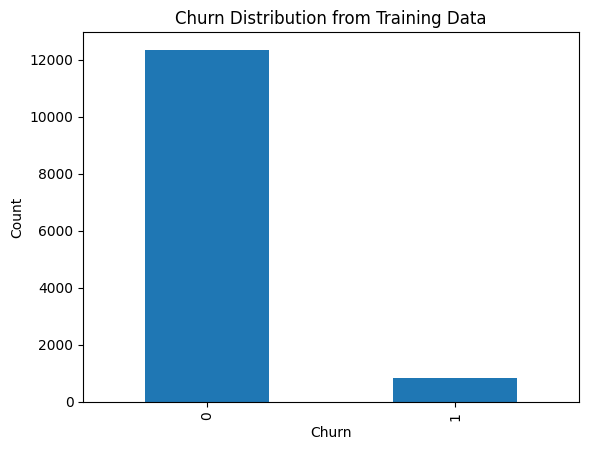

In [ ]:
# visualizing the data
data['churn_target'].value_counts().plot(kind='bar')

plt.title('Churn Distribution from Training Data')
plt.xlabel('Churn')
plt.ylabel('Count')

In [ ]:
labels=["Negative","Positive"]

Positive_or_not = data["churn_target"].value_counts().tolist()
values = [Positive_or_not[0], Positive_or_not[1]]

fig = px.pie(values=data["churn_target"].value_counts(), names=labels , width=700, height=400, color_discrete_sequence=["skyblue","black"]
             ,title="Positive vs Negative Classes")
fig.show()

## Multivariate analysis:

In [ ]:
# Calculate correlations with the target variable, excluding User_Id
correlations = users_clean_encoded.drop(columns=['User_Id']).corr()['churn_target'].sort_values(ascending=False)

# Display the correlations
print(correlations)

churn_target                        1.000000
Language_ar                         0.066459
Gender_Unknown                      0.033921
Avatar_Class_unknown                0.028018
Gender_FEMALE                       0.027616
Wallet_Type_WALLET_200              0.025264
time_since_last_update_x            0.021822
time_since_last_update_y            0.021822
Language_ar-MA                      0.010245
Top_10_Name_sara                    0.008545
Top_10_Name_mohamed                 0.008503
Top_10_Name_yassine                 0.008005
Wallet_Type_WALLET_MERCHANT         0.005593
Top_10_Name_Other                   0.001731
Top_10_Name_ayoub                  -0.001231
min_transaction_amount             -0.005556
Top_10_Name_omar                   -0.005791
Avatar_Class_users                 -0.006045
total_transaction_amount           -0.008066
Top_10_Name_oussama                -0.008183
Is_Online                          -0.008640
max_transaction_amount             -0.008910
avg_transa

## Make predictions (required)

Remember you should create a dataframe named `prediction_df` with exactly 104,480 entries plus a header row attempting to predict the likelihood of churn for subscriptions in `test_df`. Your submission will throw an error if you have extra columns (beyond `CustomerID` and `predicted_probaility`) or extra rows.

The file should have exactly 2 columns:
`CustomerID` (sorted in any order)
`predicted_probability` (contains your numeric predicted probabilities between 0 and 1, e.g. from `estimator.predict_proba(X, y)[:, 1]`)

The naming convention of the dataframe and columns are critical for our autograding, so please make sure to use the exact naming conventions of `prediction_df` with column names `CustomerID` and `predicted_probability`!

### Example prediction submission:

The code below is a very naive prediction method that simply predicts churn using a Dummy Classifier. This is used as just an example showing the submission format required. Please change/alter/delete this code below and create your own improved prediction methods for generating `prediction_df`.

**PLEASE CHANGE CODE BELOW TO IMPLEMENT YOUR OWN PREDICTIONS**

## Data splitting:

In [ ]:
from sklearn.model_selection import train_test_split

# Splitting the data
X = data.drop(['churn_target', 'User_Id'], axis=1)  # Features
y = data['churn_target']  # Target variable

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Display the shapes of the resulting datasets
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

# Using Decision Tree Classifier

In [ ]:
# training the model
tree = DecisionTreeClassifier(random_state=42, max_depth=5, min_samples_split=10, class_weight={0: 1, 1: 20})

In [ ]:
# fitting the model
tree.fit(X_train, y_train)

In [ ]:
importances = tree.feature_importances_
indices = np.argsort(importances)[::-1]

print("Feature ranking:")
for i, idx in enumerate(indices):
    print("%d. %s (%f)" % (i + 1, X_train.columns[idx], importances[idx]))

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

# Predicting the labels for X_test
y_pred = tree.predict(X_test)

# Calculating accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.2f}")

# Calculating precision
precision = precision_score(y_test, y_pred)
print(f"Precision: {precision:.2f}")

# Calculating recall
recall = recall_score(y_test, y_pred)
print(f"Recall: {recall:.2f}")

# Calculating F1-score
f1 = f1_score(y_test, y_pred)
print(f"F1 Score: {f1:.2f}")

# Generating the confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(conf_matrix)

# Generating a classification report
class_report = classification_report(y_test, y_pred)
print("Classification Report:")
print(class_report)

# Using Random Forest Classifier

In [ ]:
from sklearn.ensemble import RandomForestClassifier
rf_model = RandomForestClassifier(random_state=42, n_estimators=100, max_depth=10, class_weight={0: 1, 1: 20})
rf_model.fit(X_train, y_train)

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

# Evaluate the model on y_test
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.2f}")
print(f"Precision: {precision:.2f}")
print(f"Recall: {recall:.2f}")
print(f"F1 Score: {f1:.2f}")

# Display the classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Display the confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# Display important features
importances = tree.feature_importances_  # Assuming DecisionTreeClassifier was used
indices = np.argsort(importances)[::-1]

print("\nFeature Importance Ranking:")
for i, idx in enumerate(indices[:10]):  # Display top 10 features
    print(f"{i + 1}. {X_test.columns[idx]} ({importances[idx]:.4f})")

# GridSearchCV

In [ ]:
parameters = {
    'n_estimators': [100, 200, 300, 400, 500],
    'max_depth': [None, 3, 5, 7, 10],
    'min_samples_split': [2, 5, 10, 15, 20],
    'min_samples_leaf': [1, 2, 5, 10, 15],
}

In [ ]:
rf_model = RandomForestClassifier(random_state=0)

In [ ]:
rf_model.fit(X_train, y_train)

In [ ]:
# performing grid search with cross validation
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer, f1_score

# Define a custom scorer based on F1 score
f1_scorer = make_scorer(f1_score, greater_is_better=True)

# Update GridSearchCV to use F1 score as the evaluation metric
grid_search = GridSearchCV(estimator=rf_model, param_grid=parameters, scoring=f1_scorer, cv=5, n_jobs=-1)


grid_search = GridSearchCV(estimator=rf_model, param_grid=parameters, cv=5, n_jobs=-1)
grid_search.fit(X_train, y_train)

In [ ]:
# getting the best model and its parameters
best_model = grid_search.best_estimator_
best_model_params = grid_search.best_params_

In [ ]:
# predicted_probability = rf_model.predict_proba(X_test)[:, 1] # for random forest model
predicted_probability = best_model.predict_proba(X_test)[:, 1] # for grid search model

In [ ]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Display grid search statistics

# Convert cv_results_ to a DataFrame for better readability
grid_search_results = pd.DataFrame(grid_search.cv_results_)

# Display the top 5 parameter combinations sorted by mean test score
top_results = grid_search_results.sort_values(by='mean_test_score', ascending=False).head(5)

# Display relevant columns
print(top_results[['mean_test_score', 'std_test_score', 'params']])
# Display the best parameters and score
print("Best Parameters:", best_model_params)
print("Best Score:", grid_search.best_score_)

# Train the best model on the entire training set
best_model.fit(X_train, y_train)

# Evaluate the best model on the test set
y_pred_best = best_model.predict(X_test)
y_pred_prob_best = best_model.predict_proba(X_test)[:, 1]

# Display evaluation metrics

print("Accuracy:", accuracy_score(y_test, y_pred_best))
print("Precision:", precision_score(y_test, y_pred_best))
print("Recall:", recall_score(y_test, y_pred_best))
print("F1 Score:", f1_score(y_test, y_pred_best))
print("ROC AUC Score:", roc_auc_score(y_test, y_pred_prob_best))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_best))

# Display the confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_best))

# Random Forest Classifier with Feature Selection

In [ ]:
X_train = train_df.drop(['CustomerID','Churn'], axis=1)
y_train = train_df['Churn']

In [ ]:
X_test = test_df.drop(['CustomerID'], axis=1)

In [ ]:
label_encoder = LabelEncoder()
for col in categorical_columns:
    X_train[col] = label_encoder.fit_transform(X_train[col])
    X_test[col] = label_encoder.transform(X_test[col])

In [ ]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=0)

In [ ]:
rf_model.fit(X_train, y_train)

In [ ]:
feature_importances = rf_model.feature_importances_
importance_df = pd.DataFrame({'feature': X_train.columns, 'importance': feature_importances})
importance_df = importance_df.sort_values('importance', ascending=False)
importance_df

In [ ]:
selected_features = importance_df[importance_df['importance'] > 0.01]['feature'].values
selected_features

In [ ]:
new_X_train = X_train[selected_features]
new_X_test = X_test[selected_features]

In [ ]:
categorical_columns = new_X_train.select_dtypes(include=['object', 'string']).columns
label_encoder = LabelEncoder()
for col in categorical_columns:
    new_X_train[col] = label_encoder.fit_transform(new_X_train[col])
    new_X_test[col] = label_encoder.transform(new_X_test[col])

In [ ]:
# defining the class weights
class_weights = {0: 1, 1: 4}

In [ ]:
rf_model = RandomForestClassifier(n_estimators=100, class_weight=class_weights, random_state=0)
rf_model.fit(new_X_train, y_train)

# Using XGBoost Classifier

In [ ]:
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder

In [ ]:
X_train = train_df.drop(['CustomerID','Churn'], axis=1)
y_train = train_df['Churn']
X_test = test_df.drop(['CustomerID'], axis=1)

## Feature Engineering

In [ ]:
# Usage Patterns
X_train['AverageViewingDurationPerWeek'] = X_train['AverageViewingDuration'] / (X_train['ViewingHoursPerWeek'] + 1e-8)
X_test['AverageViewingDurationPerWeek'] = X_test['AverageViewingDuration'] / (X_test['ViewingHoursPerWeek'] + 1e-8)

In [ ]:
# Aggregated Features
X_train['AverageViewingDurationBySubscriptionType'] = X_train.groupby('SubscriptionType')['AverageViewingDuration'].transform('mean')
X_test['AverageViewingDurationBySubscriptionType'] = X_test.groupby('SubscriptionType')['AverageViewingDuration'].transform('mean')

In [ ]:
# Interaction Ratios
X_train['ContentDownloadsToViewingHoursRatio'] = X_train['ContentDownloadsPerMonth'] / (X_train['ViewingHoursPerWeek'] * 4 + 1e-8)
X_test['ContentDownloadsToViewingHoursRatio'] = X_test['ContentDownloadsPerMonth'] / (X_test['ViewingHoursPerWeek'] * 4 + 1e-8)

In [ ]:
label_encoder = LabelEncoder()
categorical_columns = X_train.select_dtypes(include=['object', 'string']).columns
for col in categorical_columns:
    X_train[col] = label_encoder.fit_transform(X_train[col])
    X_test[col] = label_encoder.transform(X_test[col])

In [ ]:
xgb_model = XGBClassifier(n_estimators=100, random_state=0)
xgb_model.fit(X_train, y_train)

# Logistic Regression

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

In [ ]:
train_df = pd.read_csv('train.csv')
test_df = pd.read_csv('test.csv')

In [ ]:
X_train = train_df.drop(['Churn', 'CustomerID'], axis=1)
y_train = train_df['Churn']
X_test = test_df.drop('CustomerID', axis=1)

In [ ]:
categorical_columns = X_train.select_dtypes(include=['object', 'string']).columns
label_encoder = LabelEncoder()
for col in categorical_columns:
    X_train[col] = label_encoder.fit_transform(X_train[col])
    X_test[col] = label_encoder.transform(X_test[col])

In [ ]:
# feature scaling
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
logreg_model = LogisticRegression(random_state=0, max_iter=1000)
logreg_model.fit(X_train, y_train)

In [ ]:
predicted_probability = logreg_model.predict_proba(X_test)[:, 1]

# Improved Logistic Regression

In [ ]:
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegressionCV
from sklearn.pipeline import Pipeline

In [ ]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
# Perform feature selection
feature_selector = SelectKBest(f_classif, k=8)
X_train_selected = feature_selector.fit_transform(X_train, y_train)
X_test_selected = feature_selector.transform(X_test)

In [ ]:
logreg_model = LogisticRegressionCV(random_state=0, max_iter=1000)

In [ ]:
pipeline = Pipeline([('feature_selector', feature_selector), ('logreg_model', logreg_model)])
pipeline.fit(X_train, y_train)

In [ ]:
predicted_probability = pipeline.predict_proba(X_test)[:, 1]

In [ ]:
y_train.value_counts()

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report, confusion_matrix

# Predict the labels for X_test
y_pred = logreg_model.predict(X_test_selected)

# Predict probabilities for X_test
y_pred_prob = pipeline.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_pred_prob)

# Display evaluation metrics
print(f"Accuracy: {accuracy:.2f}")
print(f"Precision: {precision:.2f}")
print(f"Recall: {recall:.2f}")
print(f"F1 Score: {f1:.2f}")
print(f"ROC AUC Score: {roc_auc:.2f}")

# Display the classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Display the confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

In [ ]:
x = pd.Series(y_pred)
x.value_counts()

# Using SVM Classifier

In [ ]:
from sklearn.svm import SVC

In [ ]:
sns.heatmap(data.drop(["User_Id"], axis = 1).corr()['churn_target'].sort_values(ascending=False).to_frame(), annot=True)

plt.title('Correlation of Features with Churn', fontsize=12, fontweight='bold', pad=50)
plt.show()

In [ ]:
categorical_columns = X_train.select_dtypes(include=['object', 'string']).columns
label_encoder = LabelEncoder()
for col in categorical_columns:
    X_train[col] = label_encoder.fit_transform(X_train[col])
    X_test[col] = label_encoder.transform(X_test[col])

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

feature_selector = SelectKBest(f_classif, k=12)
X_train_selected = feature_selector.fit_transform(X_train, y_train)
X_test_selected = feature_selector.transform(X_test)

In [ ]:
svm_model = SVC(kernel='rbf', random_state=0, probability=True)
# Penalize the 0 class and weight the 1 class
svm_model.fit(X_train, y_train, sample_weight=np.where(y_train == 1, 20, 1))

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, roc_auc_score

# Predicting the labels for X_test
y_pred_svm = svm_model.predict(X_test)

# Predicting probabilities for X_test
y_pred_prob_svm = svm_model.predict_proba(X_test)[:, 1]

# Calculating accuracy
accuracy_svm = accuracy_score(y_test, y_pred_svm)
print(f"Accuracy: {accuracy_svm:.2f}")

# Calculating precision
precision_svm = precision_score(y_test, y_pred_svm)
print(f"Precision: {precision_svm:.2f}")

# Calculating recall
recall_svm = recall_score(y_test, y_pred_svm)
print(f"Recall: {recall_svm:.2f}")

# Calculating F1-score
f1_svm = f1_score(y_test, y_pred_svm)
print(f"F1 Score: {f1_svm:.2f}")

# Calculating ROC AUC score
roc_auc_svm = roc_auc_score(y_test, y_pred_prob_svm)
print(f"ROC AUC Score: {roc_auc_svm:.2f}")

# Generating the confusion matrix
conf_matrix_svm = confusion_matrix(y_test, y_pred_svm)
print("Confusion Matrix:")
print(conf_matrix_svm)

# Generating a classification report
class_report_svm = classification_report(y_test, y_pred_svm)
print("Classification Report:")
print(class_report_svm)

# Using Neural Networks

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
import pandas as pd
from sklearn.preprocessing import LabelEncoder, StandardScaler

In [ ]:
from sklearn.utils import resample

# Separate the minority and majority classes
minority_class = data[data['churn_target'] == 1]
majority_class = data[data['churn_target'] == 0]

# Oversample the minority class
minority_oversampled = resample(minority_class,
                                replace=True,  # Sample with replacement
                                n_samples=len(majority_class),  # Match majority class size
                                random_state=42)  # For reproducibility

# Combine the oversampled minority class with the majority class
balanced_data = pd.concat([majority_class, minority_oversampled])

# Shuffle the dataset
balanced_data = balanced_data.sample(frac=1, random_state=42).reset_index(drop=True)

# Display the class distribution
print(balanced_data['churn_target'].value_counts())

In [ ]:
categorical_columns = X_train.select_dtypes(include=['object', 'string']).columns
label_encoder = LabelEncoder()
for col in categorical_columns:
    X_train[col] = label_encoder.fit_transform(X_train[col])
    X_test[col] = label_encoder.transform(X_test[col])

In [ ]:
from tensorflow.keras import backend as K

model = Sequential()
model.add(Dense(32, activation='relu', input_dim=X_train.shape[1]))
model.add(Dense(16, activation='relu'))
model.add(Dense(1, activation='sigmoid'))

# Adjust the loss function to penalize more on 1

def weighted_binary_crossentropy(y_true, y_pred):
    weight_for_1 = 5.0  # Adjust this weight to penalize more on 1
    weight_for_0 = 1.0
    loss = - (weight_for_1 * y_true * K.log(y_pred + K.epsilon()) + weight_for_0 * (1 - y_true) * K.log(1 - y_pred + K.epsilon()))
    return K.mean(loss)

model.compile(optimizer='adam', loss=weighted_binary_crossentropy, metrics=['f1_score', 'accuracy'])

In [ ]:
model.fit(X_train, y_train, epochs=10, batch_size=32, verbose=1)

In [ ]:
predicted_probability = model.predict(X_test)[:, 0]

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report, confusion_matrix

# Predict probabilities and labels for the test set
y_pred_prob_nn = model.predict(X_test).flatten()
y_pred_nn = (y_pred_prob_nn > 0.5).astype(int)

# Calculate evaluation metrics
accuracy_nn = accuracy_score(y_test, y_pred_nn)
precision_nn = precision_score(y_test, y_pred_nn)
recall_nn = recall_score(y_test, y_pred_nn)
f1_nn = f1_score(y_test, y_pred_nn)
roc_auc_nn = roc_auc_score(y_test, y_pred_prob_nn)

# Display evaluation metrics
print(f"Accuracy: {accuracy_nn:.2f}")
print(f"Precision: {precision_nn:.2f}")
print(f"Recall: {recall_nn:.2f}")
print(f"F1 Score: {f1_nn:.2f}")
print(f"ROC AUC Score: {roc_auc_nn:.2f}")

# Display classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred_nn))

# Display confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_nn))

In [ ]:
### PLEASE CHANGE THIS CODE TO IMPLEMENT YOUR OWN PREDICTIONS

# # Combine predictions with label column into a dataframe
prediction_df = pd.DataFrame({'CustomerID': test_df[['CustomerID']].values[:, 0],
                              'predicted_probability': predicted_probability})

In [ ]:
### PLEASE CHANGE THIS CODE TO IMPLEMENT YOUR OWN PREDICTIONS

# # View our 'prediction_df' dataframe as required for submission.
# # Ensure it should contain 104,480 rows and 2 columns 'CustomerID' and 'predicted_probaility'
print(prediction_df.shape)
prediction_df.head(10)

**PLEASE CHANGE CODE ABOVE TO IMPLEMENT YOUR OWN PREDICTIONS**

## Final Tests - **IMPORTANT** - the cells below must be run prior to submission

Below are some tests to ensure your submission is in the correct format for autograding. The autograding process accepts a csv `prediction_submission.csv` which we will generate from our `prediction_df` below. Please run the tests below an ensure no assertion errors are thrown.

In [ ]:
# FINAL TEST CELLS - please make sure all of your code is above these test cells

# Writing to csv for autograding purposes
prediction_df.to_csv("prediction_submission.csv", index=False)
submission = pd.read_csv("prediction_submission.csv")

assert isinstance(submission, pd.DataFrame), 'You should have a dataframe named prediction_df.'

In [ ]:
# FINAL TEST CELLS - please make sure all of your code is above these test cells

assert submission.columns[0] == 'CustomerID', 'The first column name should be CustomerID.'
assert submission.columns[1] == 'predicted_probability', 'The second column name should be predicted_probability.'

In [ ]:
# FINAL TEST CELLS - please make sure all of your code is above these test cells

assert submission.shape[0] == 104480, 'The dataframe prediction_df should have 104480 rows.'

In [ ]:
# FINAL TEST CELLS - please make sure all of your code is above these test cells

assert submission.shape[1] == 2, 'The dataframe prediction_df should have 2 columns.'

In [ ]:
# FINAL TEST CELLS - please make sure all of your code is above these test cells

## This cell calculates the auc score and is hidden. Submit Assignment to see AUC score.

## SUBMIT YOUR WORK!

Once we are happy with our `prediction_df` and `prediction_submission.csv` we can now submit for autograding! Submit by using the blue **Submit Assignment** at the top of your notebook. Don't worry if your initial submission isn't perfect as you have multiple submission attempts and will obtain some feedback after each submission!